# 06 基于 NetworkX 的匹配问题算法

> **模块**：图论与网络 ｜ **数据**：无（内置示例） ｜ **依赖**：numpy、pandas、matplotlib、networkx

## 1. 问题背景

匹配问题是运筹学的重要问题之一，也是图论的重要内容，它提供了解决“人员分配问题”和“最优分配问题”一种新的思想。图论中的匹配问题是指在一个图中找到一个边集，使得这些边互不相交，且每个顶点最多只与一条边相连。匹配问题可以应用于很多场景，例如稳定婚姻问题、任务分配问题等等。


## 2. 学习目标

- 掌握 Kuhn-Munkres 算法的思路
- 掌握使用 NetworkX 计算最大权完美匹配


## 3. 环境与数据

- Jupyter 开发环境
- Python 3.10


## 4. 方法与实现

### 4.1 基本概念

#### 4.1.1 二分图

定义1.若无向图G=(V,E)的顶点可以分成X，Y两个子集，两个子集交集为空，并且任意边的两个端点都分属于两个集合（ $X∪Y = V, X∩Y=∅$），则称图G为一个二分图。

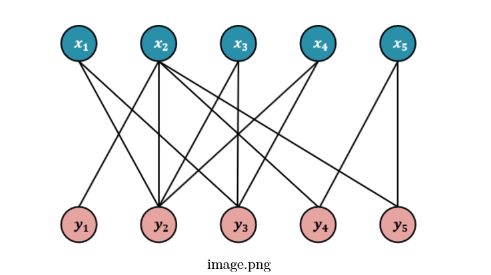

二分图是图论中的一种特殊模型。

#### 4.1.2 匹配

定义2.若M是图G=(V,E)的边子集，且M中的任意两条边在G中不相邻，则称M为G中的一个**匹配**，M中的每条边的两个端点称为是**M-饱和的**。

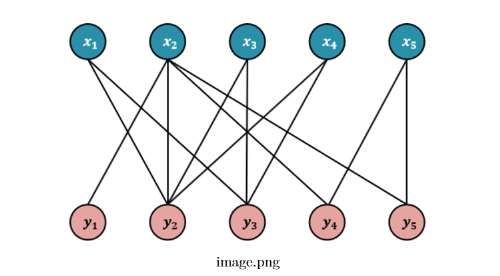

#### 4.1.3 完美匹配

定义3.若图G中每个顶点均被M匹配时，称M为G中的一个完美匹配。

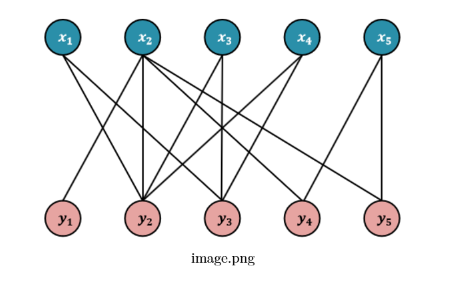

#### 4.1.4 最大匹配

定义4.图G中边数最多的匹配M，称为G中的一个最大匹配。

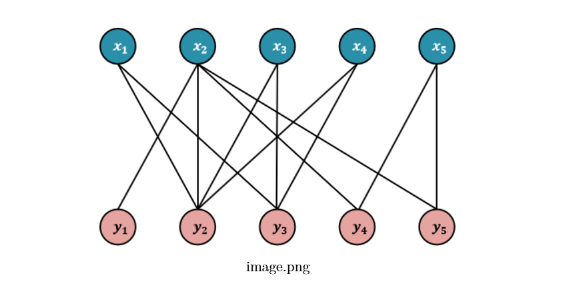

### 4.2 最佳匹配问题

公司有n名工作人员（$x_1,x_2,...,x_n$），他们每个人都能承担n项工作（$y_1,y_2,...,y_n$）的其中若干项，因为每个人的特征不同，所以对每项工作创造的价值也有所不同。问如何安排，使得他们的总创造价值最大？

#### 4.2.1 Kuhn-Munkres 算法

假设要分配5个人做5项不同工作，每个人做不同工作产生的效益由一下邻接矩阵$W$表示。

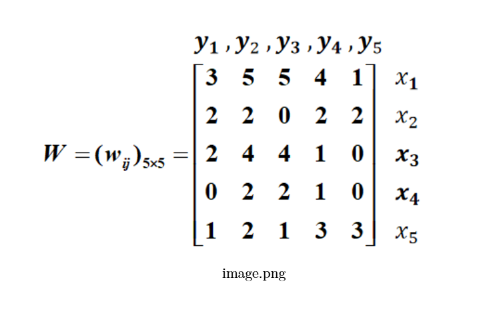

$w_{ij}(i,j=1,2,3,4,5)$表示第i个人干第j项工作的效益，试求使效益达到最大的分配方案。

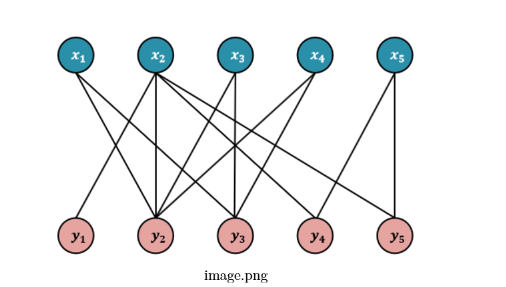

Kuhn和Munkres设计了求最佳匹配的有效算法，他们把求最佳匹配的问题转化成可用匈牙利算法求另一个图的完美匹配的问题。

**顶点标号与可行顶点标号**

图$G$的顶点标号是从顶点集到正整数集的一个映射。用$l(x)$表示顶点$v$的标号，$w(xy)$表示边$(x,y)$的权。对于赋权的二分图$G=(X,Y)$，若对每条边$e = (x,y)$，均有了$l(x)+l(y)≥w(xy)$，则称这个标号为$G$的一个可行的顶点标号。

一般的，我们会这样取顶点标号的值：$l(y)$全部赋值为0，而$l(x)$取得是和顶点x相邻接的所有的点之间的权重的最大值。

**相等子图**

设$G$是一个赋权二分图，$l$是$G$的可行顶点标号，边$(x,y)$的权为$w(xy)$，令$E_l = \{xy∈E(G)|l(x)+l(y)=w(xy)\}$，G中以$E_l$为边集生成子图称为G的$l$相等子图，记为$G_l$

如下图为以上二分图的相等子图$G_l$

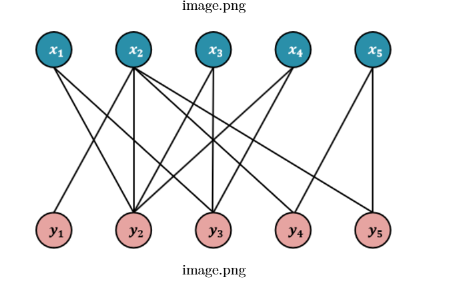

定理1.设l是赋权二分图G的一个可行顶点标号，若相等子图$G_l$有完美匹配，则该完美匹配是G的最大权完美匹配。

定理2.G为二分图，X与Y是顶点集的划分，G中存在把X中顶点完美匹配的充要条件是，$∀S⊂X$，有$|N(S)|≥|S|$，其中$N(S)$是$S$中顶点的临集。

#### 4.2.2 Kuhn-Munkres 算法思想

1. **初始可行顶点标号**：
- 首先给出赋权二分图 $ G $ 的任意一个可行顶点标号，然后确定相等子图 $ G_l $。

2. **在 $ G_l $ 中执行匈牙利算法**：
- 在 $ G_l $ 中选取一个完美匹配 $ M $。

3. **判断完美匹配**：
- 若 $ X $ 中的顶点皆被 $ M $ 匹配，停止，$ M $ 即为 $ G $ 的最大权完美匹配；
- 否则，取 $ G_l $ 中未被 $ M $ 匹配的顶点 $ u $，令 $ S = \{u\} $，$ T = \emptyset $。

4. **邻接顶点判断**：
- 若 $ N_{G_l}(S) \supset T $，则转到第 4 步；
- 若 $ N_{G_l}(S) = T $，则执行以下操作：
- 计算 $ \alpha_l = \min \{ l(x) + l(y) - w(xy) \mid x \in S, y \notin T \} $
- 更新标号：

$$
\bar{l}(v) =
\begin{cases}
l(v) - \alpha_l & \quad \text{如果 } v \in S \\
l(v) + \alpha_l & \quad \text{如果 } v \in T \\
l(v) & \quad \text{其他}
\end{cases}

$$

- 然后更新标号：$ l = \bar{l} $， $ G_l = G_{\bar{l}} $

5. **选择邻接顶点**：
- 选 $ N_{G_l}(S) - T $ 中的一顶点 $ y $，若 $ y $ 已被 $ M $ 匹配且 $ yz \in M $，则：
- $ S = S \cup \{z\} $
- $ T = T \cup \{y\} $
- 转到第 3 步；
- 否则，取 $ G_l $ 中一个 $ M $ 可增广路径 $ P(x,y) $，转到第 2 步。

以上完美匹配就是二分图G的最大权完美匹配。

#### 4.2.3 使用 NetworkX 实现

使用 NetworkX 计算无向图 G 的最大加权匹配可以通过以下函数实现：

```python
networkx.algorithms.matching.max_weight_matching(G, maxcardinality=False, weight='weight')
```

- **G**：无向图
- **maxcardinality**：布尔值，默认值为 `False`。若为 `True`，则计算所有最大基数匹配中与最大权重匹配的最大基数。
- **weight**：邻接矩阵中用于表示权重的字段名称，默认为 `'weight'`。


In [1]:
import networkx as nx  # 导入networkx库
import matplotlib.pyplot as plt  # 导入matplotlib.pyplot库
import numpy as np  # 导入numpy库
import pandas as pd  # 导入pandas库
from networkx.algorithms.matching import max_weight_matching  # 导入networkx匹配算法中的max_weight_matching函数

a = np.array([[3, 5, 5, 4, 1],  # 创建矩阵w
              [2, 2, 0, 2, 2],
              [2, 4, 4, 1, 0],
              [0, 2, 2, 1, 0],
              [1, 2, 1, 3, 3]])

b = np.zeros((10, 10))  # 创建一个10×10的全0矩阵
b[0:5, 5:] = a  # 这里需要的邻接矩阵顶点集为V={x1,x2,x3,x4,x5,y1,y2,y3,y4,y5}，也就是构建10×10的矩阵，但只有右上角5×5有数值。
b  # 输出矩阵b


array([[0., 0., 0., 0., 0., 3., 5., 5., 4., 1.],
       [0., 0., 0., 0., 0., 2., 2., 0., 2., 2.],
       [0., 0., 0., 0., 0., 2., 4., 4., 1., 0.],
       [0., 0., 0., 0., 0., 0., 2., 2., 1., 0.],
       [0., 0., 0., 0., 0., 1., 2., 1., 3., 3.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [2]:
# 创建无向图
G = nx.Graph(b)
# 得到s0为无向图的最大权匹配
s0 = max_weight_matching(G)
s = [sorted(w) for w in s0]
s

[[1, 5], [4, 9], [2, 7], [0, 8], [3, 6]]

这里得到的是人员和工作的匹配结果。0\~4表示人员，5\~9表示工作。

In [3]:
L1 = [x[0] for x in s]  # 获取人员编号
L1 = np.array(L1) + 1   # 将人员编号调整为从1开始
L2 = [x[1] for x in s]  # 获取工作编号
L2 = np.array(L2) - 4   # 将工作编号调整为从实际编号开始
c = a[L1-1, L2-1]       # 提取对应的效益
d = c.sum()             # 计算总的效益
print("工作分配对应关系为：\n人员编号：", L1)  # 打印人员编号
print("工作编号：", L2)      # 打印工作编号
print("匹配对应收益为：", c)  # 打印匹配对应收益
print("总的效益为：", d)     # 打印总的效益


工作分配对应关系为：
人员编号： [2 5 3 1 4]
工作编号： [1 5 3 4 2]
匹配对应收益为： [2 3 4 4 2]
总的效益为： 15


即分配第一个人去做第4项工作，第二个人去做第1项工作，第三个人去做第3项工作，第四个人去做第2项工作，第五个人去做第5项工作，总的效益为15。


## 5. 小结

本次实验介绍了匹配问题算法中使用的基础概念和Kuhn-Munkres算法的基本思路，并且通过一个实例使用networkx库计算二分图的最大权完美匹配。

通过本次实验需要掌握以下内容：
- 掌握Kuhn-Munkres算法的思路
- 掌握使用networkx计算最大权完美匹配
